<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%201-10/Experiment%204%3A%20Entropy%2C%20Cross-Entropy%20and%20KL%20Divergence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Observed Weather Entropy H(P): 1.4855 bits

Model 1 -> Cross-Entropy: 1.4870 | KL Divergence: 0.0015 | H(P)+KL: 1.4870

Model 2 -> Cross-Entropy: 1.8821 | KL Divergence: 0.3966 | H(P)+KL: 1.8821

KL Asymmetry: D_KL(P||Q2) = 0.2749 vs D_KL(Q2||P) = 0.2749


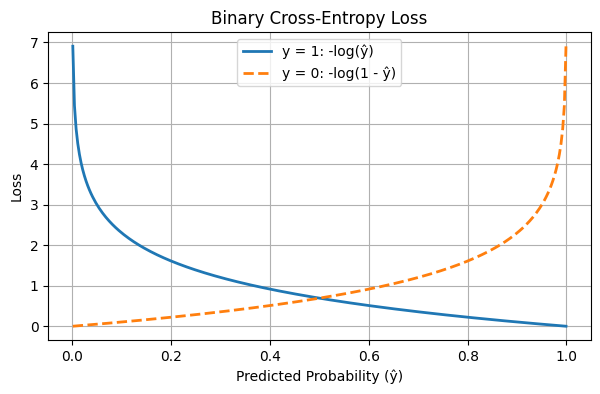

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import rel_entr

P = np.array([0.50, 0.30, 0.20])
Q1 = np.array([0.48, 0.32, 0.20])
Q2 = np.array([0.20, 0.30, 0.50])

H_P = -np.sum(P * np.log2(P))
print(f"Observed Weather Entropy H(P): {H_P:.4f} bits")

for name, Q in [("Model 1", Q1), ("Model 2", Q2)]:
    ce = -np.sum(P * np.log2(Q))
    kl = np.sum(P * np.log2(P / Q))
    print(f"\n{name} -> Cross-Entropy: {ce:.4f} | KL Divergence: {kl:.4f} | H(P)+KL: {H_P + kl:.4f}")

kl_pq = np.sum(rel_entr(P, Q2))
kl_qp = np.sum(rel_entr(Q2, P))
print(f"\nKL Asymmetry: D_KL(P||Q2) = {kl_pq:.4f} vs D_KL(Q2||P) = {kl_qp:.4f}")

y_hat = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(7, 4))
plt.plot(y_hat, -np.log(y_hat), label="y = 1: -log(ŷ)", linewidth=2)
plt.plot(y_hat, -np.log(1 - y_hat), label="y = 0: -log(1 - ŷ)", linewidth=2, linestyle="--")
plt.title("Binary Cross-Entropy Loss")
plt.xlabel("Predicted Probability (ŷ)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()